In [2]:
# ==============================
# IMPORT REQUIRED LIBRARIES
# ==============================

import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# NLP
import re
import string

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# ==============================
# LOAD STARTUP FAILURE DATASET
# ==============================

file_path = r"C:\Users\shubham kharb\Desktop\Minor Project\Datasets\startup_failure_analysis.csv"

df_failure = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
# Dataset shape
print("Dataset Shape:", df_failure.shape)

print("\nColumn Names:")
print(df_failure.columns.tolist())

Dataset Shape: (254, 4)

Column Names:
['startup_name', 'description', 'dimension', 'failure_reason']


In [5]:
df_failure.head()

,startup_name,description,dimension,failure_reason
0,Quibi,"A streaming service for short-form, high-produ...",Market Size,the startup targeted a market that was too sma...
1,Juicero,A $400 Wi-Fi connected machine designed to squ...,Market Size,the startup targeted a market that was too sma...
2,Segway,A self-balancing personal transporter that was...,Market Size,the startup targeted a market that was too sma...
3,Blockbuster,A massive brick-and-mortar video rental empire...,Competition,the startup was outcompeted or failed to diffe...
4,Jawbone,An early pioneer in Bluetooth earpieces and fi...,Competition,the startup was outcompeted or failed to diffe...


In [6]:
df_failure.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 254 entries, 0 to 253
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   startup_name    254 non-null    object
 1   description     254 non-null    object
 2   dimension       254 non-null    object
 3   failure_reason  254 non-null    object
dtypes: object(4)
memory usage: 8.1+ KB


In [7]:
print("Missing Values:")
print(df_failure.isnull().sum())

Missing Values:
startup_name      0
description       0
dimension         0
failure_reason    0
dtype: int64


In [8]:
df_failure.describe(include='all').T

,count,unique,top,freq
startup_name,254,202,Moped,3
description,254,253,It was a mobile payment startup that raised la...,2
dimension,254,6,Execution Risk,52
failure_reason,254,244,the startup targeted a market that was too sma...,3


In [9]:
# ==========================================
# CHECK FAILURE DIMENSIONS
# ==========================================

print("Number of failure dimensions:", df_failure['dimension'].nunique())

print("\nFailure Dimension Distribution:")
print(df_failure['dimension'].value_counts())

Number of failure dimensions: 6

Failure Dimension Distribution:
dimension
Execution Risk    52
Monetisation      50
Competition       46
Market Size       43
Timing            34
Moat Strength     29
Name: count, dtype: int64


In [10]:
# ==========================================
# PREPARE DATA FOR NLP
# ==========================================

# Input feature
X = df_failure['description']

# Target
y = df_failure['dimension']

print("Input feature: description")
print("Target: dimension")

print("\nNumber of samples:", len(X))
print("Number of classes:", y.nunique())

Input feature: description
Target: dimension

Number of samples: 254
Number of classes: 6


In [11]:
# ==========================================
# TRAIN TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 203
Testing samples: 51


In [12]:
# ==========================================
# TF-IDF VECTORIZATION
# ==========================================

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words='english',
    ngram_range=(1, 2),
    max_features=5000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF training shape:", X_train_tfidf.shape)
print("TF-IDF testing shape:", X_test_tfidf.shape)

TF-IDF training shape: (203, 5000)
TF-IDF testing shape: (51, 5000)


In [13]:
# ==========================================
# TRAIN NLP CLASSIFICATION MODEL
# ==========================================

from sklearn.linear_model import LogisticRegression

nlp_model = LogisticRegression(
    max_iter=2000,
    class_weight='balanced',
    random_state=42
)

nlp_model.fit(X_train_tfidf, y_train)

print("NLP model trained successfully!")

NLP model trained successfully!


In [14]:
# ==========================================
# NLP PREDICTIONS
# ==========================================

y_pred = nlp_model.predict(X_test_tfidf)

print("Predictions generated successfully!")
print("\nFirst 10 predictions:")
print(y_pred[:10])

Predictions generated successfully!

First 10 predictions:
['Timing' 'Market Size' 'Competition' 'Execution Risk' 'Competition'
 'Monetisation' 'Monetisation' 'Monetisation' 'Market Size' 'Timing']


In [15]:
# ==========================================
# MODEL EVALUATION
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.37254901960784315
Precision: 0.3659544159544159
Recall   : 0.37254901960784315
F1 Score : 0.36438690308659344

Classification Report:
                precision    recall  f1-score   support

   Competition       0.50      0.56      0.53         9
Execution Risk       0.44      0.40      0.42        10
   Market Size       0.31      0.44      0.36         9
 Moat Strength       0.20      0.17      0.18         6
  Monetisation       0.40      0.40      0.40        10
        Timing       0.25      0.14      0.18         7

      accuracy                           0.37        51
     macro avg       0.35      0.35      0.35        51
  weighted avg       0.37      0.37      0.36        51



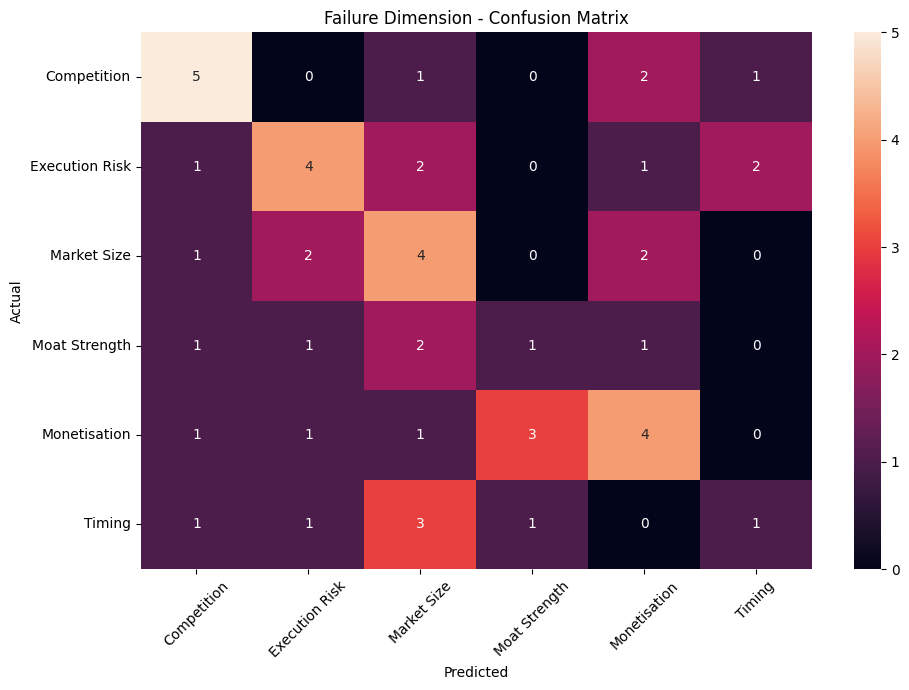

In [16]:
# ==========================================
# CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=nlp_model.classes_,
    yticklabels=nlp_model.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Failure Dimension - Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [17]:
# ==========================================
# LINEAR SVM FOR FAILURE DIMENSION
# ==========================================

from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    C=1.0,
    class_weight='balanced',
    random_state=42
)

svm_model.fit(X_train_tfidf, y_train)

print("Linear SVM trained successfully!")

Linear SVM trained successfully!


In [18]:
# ==========================================
# LINEAR SVM PREDICTIONS
# ==========================================

y_pred_svm = svm_model.predict(X_test_tfidf)

print("Predictions generated successfully!")

Predictions generated successfully!


In [19]:
# ==========================================
# LINEAR SVM EVALUATION
# ==========================================

accuracy_svm = accuracy_score(y_test, y_pred_svm)

precision_svm = precision_score(
    y_test,
    y_pred_svm,
    average='weighted',
    zero_division=0
)

recall_svm = recall_score(
    y_test,
    y_pred_svm,
    average='weighted',
    zero_division=0
)

f1_svm = f1_score(
    y_test,
    y_pred_svm,
    average='weighted',
    zero_division=0
)

print("Linear SVM Results")
print("------------------")
print("Accuracy :", accuracy_svm)
print("Precision:", precision_svm)
print("Recall   :", recall_svm)
print("F1 Score :", f1_svm)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_svm,
        zero_division=0
    )
)

Linear SVM Results
------------------
Accuracy : 0.3333333333333333
Precision: 0.32222222222222213
Recall   : 0.3333333333333333
F1 Score : 0.3251153731029892

Classification Report:
                precision    recall  f1-score   support

   Competition       0.50      0.56      0.53         9
Execution Risk       0.33      0.30      0.32        10
   Market Size       0.33      0.44      0.38         9
 Moat Strength       0.20      0.17      0.18         6
  Monetisation       0.30      0.30      0.30        10
        Timing       0.20      0.14      0.17         7

      accuracy                           0.33        51
     macro avg       0.31      0.32      0.31        51
  weighted avg       0.32      0.33      0.33        51



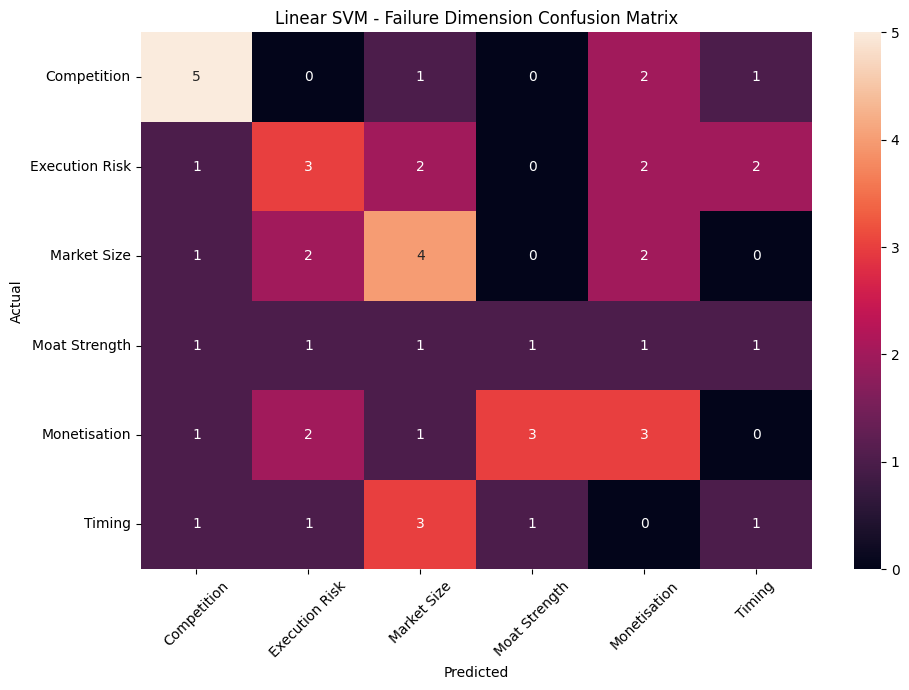

In [20]:
# ==========================================
# LINEAR SVM CONFUSION MATRIX
# ==========================================

cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    xticklabels=svm_model.classes_,
    yticklabels=svm_model.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Linear SVM - Failure Dimension Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [21]:
# ==========================================
# ANALYZE FAILURE DIMENSIONS AND REASONS
# ==========================================

print("FAILURE DIMENSIONS")
print("=" * 50)
print(df_failure['dimension'].value_counts())

print("\n\nMOST COMMON FAILURE REASONS")
print("=" * 50)
print(df_failure['failure_reason'].value_counts().head(20))

FAILURE DIMENSIONS
dimension
Execution Risk    52
Monetisation      50
Competition       46
Market Size       43
Timing            34
Moat Strength     29
Name: count, dtype: int64


MOST COMMON FAILURE REASONS
failure_reason
the startup targeted a market that was too small, niche, or shrinking                                                                                           3
the product was too early or too late for the market                                                                                                            3
the startup was outcompeted or failed to differentiate from existing players                                                                                    3
the startup had no defensible advantage and was easily copied                                                                                                   2
the startup had no clear revenue model or unsustainable unit economics                                                        

In [22]:
# ==========================================
# CREATE FAILURE KNOWLEDGE BASE
# ==========================================

failure_data = df_failure[
    ['startup_name', 'description', 'dimension', 'failure_reason']
].copy()

# Remove any accidental duplicate rows
failure_data = failure_data.drop_duplicates().reset_index(drop=True)

print("Failure knowledge base created.")
print("Number of records:", len(failure_data))

failure_data.head()

Failure knowledge base created.
Number of records: 253


,startup_name,description,dimension,failure_reason
0,Quibi,"A streaming service for short-form, high-produ...",Market Size,the startup targeted a market that was too sma...
1,Juicero,A $400 Wi-Fi connected machine designed to squ...,Market Size,the startup targeted a market that was too sma...
2,Segway,A self-balancing personal transporter that was...,Market Size,the startup targeted a market that was too sma...
3,Blockbuster,A massive brick-and-mortar video rental empire...,Competition,the startup was outcompeted or failed to diffe...
4,Jawbone,An early pioneer in Bluetooth earpieces and fi...,Competition,the startup was outcompeted or failed to diffe...


In [23]:
# ==========================================
# TF-IDF FOR FAILURE SIMILARITY
# ==========================================

from sklearn.feature_extraction.text import TfidfVectorizer

failure_tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words='english',
    ngram_range=(1, 2),
    max_features=10000,
    sublinear_tf=True
)

failure_matrix = failure_tfidf.fit_transform(
    failure_data['description']
)

print("TF-IDF vectorization completed.")
print("Matrix shape:", failure_matrix.shape)

TF-IDF vectorization completed.
Matrix shape: (253, 6168)


In [24]:
# ==========================================
# FAILURE SIMILARITY FUNCTION
# ==========================================

from sklearn.metrics.pairwise import cosine_similarity

def find_similar_failures(startup_description, top_n=5):
    
    # Convert user description into TF-IDF
    query_vector = failure_tfidf.transform(
        [startup_description]
    )
    
    # Calculate similarity with all historical failures
    similarity_scores = cosine_similarity(
        query_vector,
        failure_matrix
    ).flatten()
    
    # Get top matching records
    top_indices = similarity_scores.argsort()[::-1][:top_n]
    
    results = failure_data.iloc[top_indices].copy()
    
    # Add similarity score
    results['similarity_score'] = similarity_scores[top_indices]
    
    return results.reset_index(drop=True)

In [25]:
# ==========================================
# TEST FAILURE RETRIEVAL
# ==========================================

test_description = """
An online food delivery startup that connects customers
with local restaurants. The company depends heavily on
restaurants and has difficulty maintaining profit margins
because of high delivery and operational costs.
"""

similar_failures = find_similar_failures(
    test_description,
    top_n=5
)

similar_failures[
    [
        'startup_name',
        'dimension',
        'failure_reason',
        'similarity_score'
    ]
]

,startup_name,dimension,failure_reason,similarity_score
0,Webvan,Monetisation,It expanded too rapidly and spent heavily on i...,0.158542
1,Maple,Monetisation,The company maintained incredibly expensive pr...,0.153372
2,The Punjab Kitchen,Competition,The company charged premium prices in a highly...,0.144363
3,SpoonRocket,Competition,The company suffered from poor customer review...,0.137490
4,Melon,Monetisation,The founders realized that the complex logisti...,0.134076


In [26]:
# ==========================================
# TOP FAILURE CASE
# ==========================================

top_failure = similar_failures.iloc[0]

print("Most Similar Failed Startup:")
print("--------------------------------")

print("Startup Name:", top_failure['startup_name'])
print("Failure Dimension:", top_failure['dimension'])
print("Similarity Score:", round(top_failure['similarity_score'], 4))

print("\nFailure Reason:")
print(top_failure['failure_reason'])

Most Similar Failed Startup:
--------------------------------
Startup Name: Webvan
Failure Dimension: Monetisation
Similarity Score: 0.1585

Failure Reason:
It expanded too rapidly and spent heavily on infrastructure, running losses on every order which led to its bankruptcy


In [27]:
# ==========================================
# CHECK SIMILARITY SCORES
# ==========================================

print(similar_failures[
    ['startup_name', 'dimension', 'similarity_score']
])

         startup_name     dimension  similarity_score
0              Webvan  Monetisation          0.158542
1               Maple  Monetisation          0.153372
2  The Punjab Kitchen   Competition          0.144363
3         SpoonRocket   Competition          0.137490
4               Melon  Monetisation          0.134076


In [28]:
# ==========================================
# SAVE FAILURE NLP COMPONENT
# ==========================================

import joblib
import os

models_path = r"C:\Users\shubham kharb\Desktop\Minor Project\models"

os.makedirs(models_path, exist_ok=True)

# Save TF-IDF vectorizer
joblib.dump(
    failure_tfidf,
    os.path.join(models_path, "failure_tfidf_vectorizer.pkl")
)

# Save TF-IDF matrix
joblib.dump(
    failure_matrix,
    os.path.join(models_path, "failure_tfidf_matrix.pkl")
)

# Save failure knowledge base
joblib.dump(
    failure_data,
    os.path.join(models_path, "failure_knowledge_base.pkl")
)

print("Failure NLP component saved successfully!")

Failure NLP component saved successfully!
